ready
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  10 non-null     int64  
 1   Product   10 non-null     object 
 2   Category  10 non-null     object 
 3   Quantity  10 non-null     int64  
 4   Price     10 non-null     int64  
 5   Discount  10 non-null     float64
 6   City      10 non-null     object 
dtypes: float64(1), int64(3), object(3)
memory usage: 692.0+ bytes


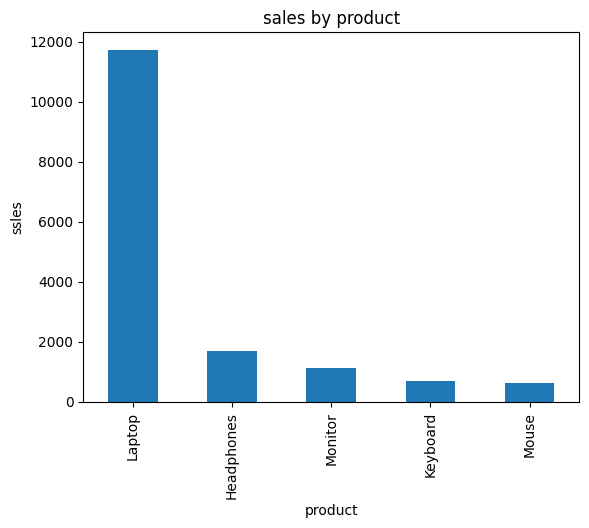

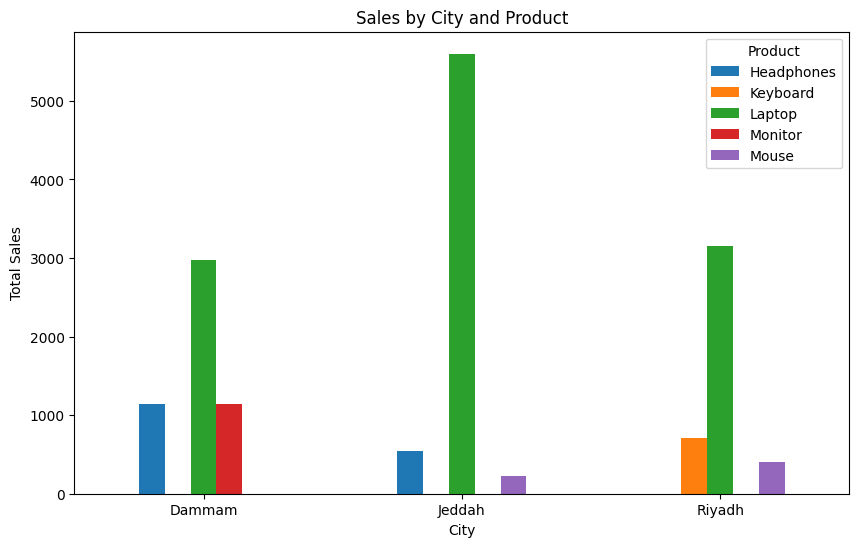

Top Product by Quantity: Mouse
Quantity Sold: 8
Top Product by Sales: Laptop
Total Sales: 11725.0
Top City by Sales: Jeddah
City Sales: 6368.0
Average Order Value: 1587.8


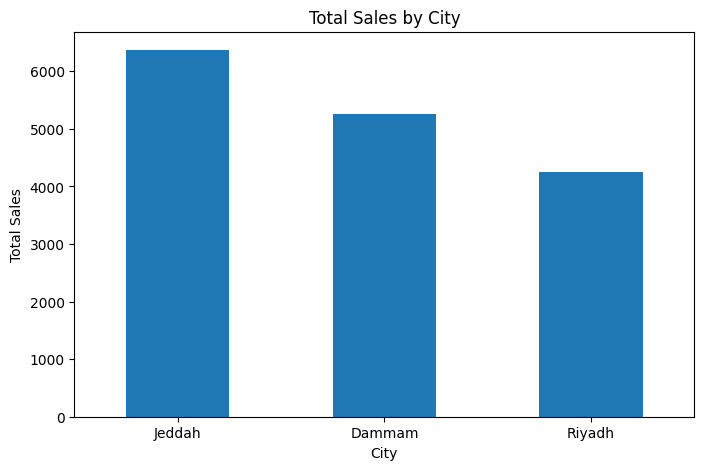

1. Best-selling product by quantity: Mouse
2. Highest-revenue product: Laptop
3. Top city by sales: Jeddah
4. Average order value: 1587.8


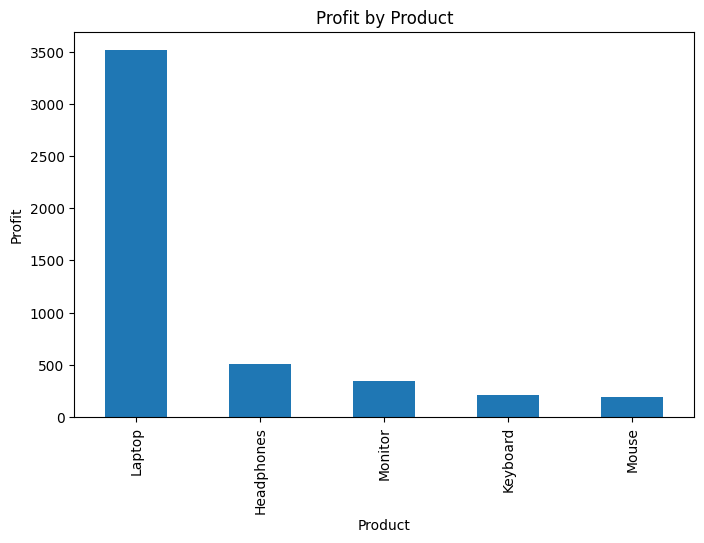

===== FINAL ANALYSIS =====
Best-selling product: Mouse
Most sold quantity: 8
Highest-sales product: Laptop
Highest sales: 11725.0
Top city: Jeddah
Top city sales: 6368.0
Most profitable product: Laptop
Highest profit: 3517.5000000000005
Average order value: 1587.8


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print ("ready")
data = {
    "Order_ID": [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010],
    "Product": ["Laptop", "Mouse", "Keyboard", "Laptop", "Headphones",
                "Mouse", "Monitor", "Keyboard", "Laptop", "Headphones"],
    "Category": ["Electronics", "Accessories", "Accessories", "Electronics",
                 "Accessories", "Accessories", "Electronics", "Accessories",
                 "Electronics", "Accessories"],
    "Quantity": [1, 3, 2, 1, 2, 5, 1, 3, 2, 4],
    "Price": [3500, 80, 150, 3500, 300, 80, 1200, 150, 3500, 300],
    "Discount": [0.10, 0.05, 0.00, 0.15, 0.10,
                 0.00, 0.05, 0.10, 0.20, 0.05],
    "City": ["Riyadh", "Jeddah", "Riyadh", "Dammam", "Jeddah",
             "Riyadh", "Dammam", "Riyadh", "Jeddah", "Dammam"]
}

df = pd.DataFrame(data)
df.shape
df.info()
df.describe()
df.isnull().sum()

df["Subtotal"] = df["Quantity"] * df["Price"]
df["Total_Sales"] = df["Subtotal"] * (1 - df["Discount"])
df[["Product", "Quantity", "Price", "Discount", "Subtotal", "Total_Sales"]]
sales_by_product = df.groupby("Product")["Total_Sales"].sum()
sales_by_product=sales_by_product.sort_values(ascending=False)
sales_by_product
sales_by_product.index[0]
sales_by_product.iloc[0]
sales_by_product.plot(kind="bar")
plt.title("sales by product")
plt.xlabel("product")
plt.ylabel("ssles")
plt.show()
sales_by_city = df.groupby("City")["Total_Sales"].sum()
sales_by_city=sales_by_city.sort_values(ascending=False)
plt.show()
avrage=df["Total_Sales"].mean()
avrage


average_by_city = df.groupby("City")["Total_Sales"].mean()
average_by_city

averarge_by_city= average_by_city.sort_values(ascending=False)
averarge_by_city
sales_by_city_product = df.groupby(["City", "Product"])["Total_Sales"].sum()
sales_by_city_product

sales_by_city_product.sort_values(ascending=False)

pivot_sales = df.pivot_table(
    values="Total_Sales",
    index="City",
    columns="Product",
    aggfunc="sum",
    fill_value=0
)

pivot_sales
pivot_sales.plot(kind="bar", figsize=(10, 6))

plt.title("Sales by City and Product")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.show()
quantity_by_product = df.groupby("Product")["Quantity"].sum()
quantity_by_product = quantity_by_product.sort_values(ascending=False)
quantity_by_product
quantity_by_product.index[0]
quantity_by_product.iloc[0]
sales_by_product.index[0]
sales_by_product.iloc[0]
sales_by_city.index[0]
sales_by_city.iloc[0]
print("Top Product by Quantity:", quantity_by_product.index[0])
print("Quantity Sold:", quantity_by_product.iloc[0])

print("Top Product by Sales:", sales_by_product.index[0])
print("Total Sales:", sales_by_product.iloc[0])

print("Top City by Sales:", sales_by_city.index[0])
print("City Sales:", sales_by_city.iloc[0])

print("Average Order Value:", df["Total_Sales"].mean())
sales_by_city.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by City")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.show()
print("1. Best-selling product by quantity:", quantity_by_product.index[0])
print("2. Highest-revenue product:", sales_by_product.index[0])
print("3. Top city by sales:", sales_by_city.index[0])
print("4. Average order value:", round(df["Total_Sales"].mean(), 2))
df["Cost"] = df["Total_Sales"] * 0.70
df["Profit"] = df["Total_Sales"] - df["Cost"]
df[["Product", "Total_Sales", "Cost", "Profit"]]
profit_by_product = df.groupby("Product")["Profit"].sum()
profit_by_product = profit_by_product.sort_values(ascending=False)

profit_by_product
profit_by_product.index[0]
profit_by_product.plot(kind="bar", figsize=(8, 5))

plt.title("Profit by Product")
plt.xlabel("Product")
plt.ylabel("Profit")

plt.show()
comparison = pd.DataFrame({
    "Sales": sales_by_product,
    "Profit": profit_by_product
})

comparison
comparison = comparison.sort_values("Sales", ascending=False)
comparison
print("===== FINAL ANALYSIS =====")

print("Best-selling product:", quantity_by_product.index[0])
print("Most sold quantity:", quantity_by_product.iloc[0])

print("Highest-sales product:", sales_by_product.index[0])
print("Highest sales:", sales_by_product.iloc[0])

print("Top city:", sales_by_city.index[0])
print("Top city sales:", sales_by_city.iloc[0])

print("Most profitable product:", profit_by_product.index[0])
print("Highest profit:", profit_by_product.iloc[0])

print("Average order value:", round(df["Total_Sales"].mean(), 2))